# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Wahyu
- **Email:** [Input Email]
- **ID Dicoding:** [Input Username]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Dataset yang dianalisis adalah **E-Commerce Public Dataset** (marketplace Olist, Brasil) berisi transaksi **September 2016 – Oktober 2018**. Karena data 2016 sangat sedikit (hanya ±330 order) dan September–Oktober 2018 belum lengkap, analisis dibatasi pada periode penuh **Januari 2017 – Agustus 2018** dan hanya pada pesanan berstatus **delivered**.

- **Pertanyaan 1:** Kategori produk apa saja yang termasuk 10 penyumbang revenue (total `price`) tertinggi dan 10 terendah pada pesanan *delivered* periode Januari 2017 – Agustus 2018, dan berapa persen total revenue yang dikontribusikan oleh 10 kategori teratas?
- **Pertanyaan 2:** Seberapa besar selisih rata-rata *review score* antara pesanan yang terlambat dan pesanan yang tepat waktu, serta di state pelanggan mana persentase keterlambatan pengiriman paling tinggi, pada pesanan *delivered* periode Januari 2017 – Agustus 2018?

**Pemeriksaan SMART**

| Elemen | Pertanyaan 1 | Pertanyaan 2 |
|---|---|---|
| Specific | Fokus pada kategori produk & revenue pesanan *delivered* | Fokus pada keterlambatan (aktual vs estimasi) terhadap review score & state |
| Measurable | Total revenue (R$), peringkat, % kontribusi top 10 | Rata-rata review score, selisih skor, % pesanan terlambat per state |
| Action-Oriented | Menentukan kategori prioritas untuk stok, promosi, dan seller acquisition | Menentukan wilayah prioritas perbaikan logistik & komunikasi estimasi |
| Relevant | Revenue adalah tujuan utama marketplace | Kepuasan pelanggan (review) menentukan retensi & reputasi |
| Time-bound | Jan 2017 – Agu 2018 | Jan 2017 – Agu 2018 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Palet warna konsisten: biru = sorotan, abu-abu = pembanding, merah = peringatan
BLUE, GREY, RED = "#2a6f97", "#c4c9cf", "#c0392b"

## Data Wrangling

### Gathering Data

Dataset terdiri dari 9 tabel yang saling berelasi:
- `orders` ⟷ `customers` (via `customer_id`), `order_items` (via `order_id`), `order_reviews`, `order_payments`
- `order_items` ⟷ `products` (via `product_id`) ⟷ `product_category_name_translation` (nama kategori Portugis → Inggris)
- `order_items` ⟷ `sellers`; `customers`/`sellers` ⟷ `geolocation` (via kode pos prefix)

#### Load tabel transaksi (orders, order_items, order_payments, order_reviews)

In [2]:
DATA = "data/"

date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
orders_df = pd.read_csv(DATA + "orders_dataset.csv", parse_dates=date_cols)
items_df = pd.read_csv(DATA + "order_items_dataset.csv")
payments_df = pd.read_csv(DATA + "order_payments_dataset.csv")
reviews_df = pd.read_csv(DATA + "order_reviews_dataset.csv",
                         parse_dates=["review_creation_date", "review_answer_timestamp"])

for name, df in {"orders": orders_df, "order_items": items_df,
                 "order_payments": payments_df, "order_reviews": reviews_df}.items():
    print(f"{name:15s} -> {df.shape[0]:>7,} baris, {df.shape[1]} kolom")
orders_df.head()

orders          ->  99,441 baris, 8 kolom
order_items     -> 112,650 baris, 7 kolom
order_payments  -> 103,886 baris, 5 kolom
order_reviews   ->  99,224 baris, 7 kolom


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


#### Load tabel master (customers, sellers, products, translation)

In [3]:
customers_df = pd.read_csv(DATA + "customers_dataset.csv")
sellers_df = pd.read_csv(DATA + "sellers_dataset.csv")
products_df = pd.read_csv(DATA + "products_dataset.csv")
translation_df = pd.read_csv(DATA + "product_category_name_translation.csv")

for name, df in {"customers": customers_df, "sellers": sellers_df,
                 "products": products_df, "translation": translation_df}.items():
    print(f"{name:15s} -> {df.shape[0]:>7,} baris, {df.shape[1]} kolom")
products_df.head()

customers       ->  99,441 baris, 5 kolom
sellers         ->   3,095 baris, 4 kolom
products        ->  32,951 baris, 9 kolom
translation     ->      71 baris, 2 kolom


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.00,287.00,1.00,225.00,16.00,10.00,14.00
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.00,276.00,1.00,"1,000.00",30.00,18.00,20.00
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.00,250.00,1.00,154.00,18.00,9.00,15.00
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.00,261.00,1.00,371.00,26.00,4.00,26.00
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.00,402.00,4.00,625.00,20.00,17.00,13.00


#### Load tabel geolocation

In [4]:
geo_df = pd.read_csv(DATA + "geolocation_dataset.csv")
print(f"geolocation     -> {geo_df.shape[0]:>7,} baris, {geo_df.shape[1]} kolom")
geo_df.head()

geolocation     -> 1,000,163 baris, 5 kolom


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.55,-46.64,sao paulo,SP
1,1046,-23.55,-46.64,sao paulo,SP
2,1046,-23.55,-46.64,sao paulo,SP
3,1041,-23.54,-46.64,sao paulo,SP
4,1035,-23.54,-46.64,sao paulo,SP


**Insight:**

- Dataset terdiri dari 9 tabel; yang terbesar adalah `geolocation` (1.000.163 baris), `order_items` (112.650 baris), dan `orders` (99.441 baris).
- Satu `customer_id` hanya berlaku untuk satu pesanan, sedangkan `customer_unique_id` (96.096 nilai unik) mengidentifikasi pelanggan yang sama. Analisis pelanggan (RFM) karena itu wajib memakai `customer_unique_id`.
- Rentang tanggal order adalah September 2016 – Oktober 2018, sehingga perlu ditentukan periode analisis yang lengkap.

### Assessing Data

#### Identifying missing value

In [5]:
tables = {"orders": orders_df, "order_items": items_df, "order_payments": payments_df,
          "order_reviews": reviews_df, "customers": customers_df, "sellers": sellers_df,
          "products": products_df, "translation": translation_df, "geolocation": geo_df}

missing = []
for name, df in tables.items():
    na = df.isna().sum()
    for col, n in na[na > 0].items():
        missing.append({"tabel": name, "kolom": col, "jumlah_missing": n, "persen": n / len(df) * 100})
pd.DataFrame(missing)

,tabel,kolom,jumlah_missing,persen
0,orders,order_approved_at,160,0.16
1,orders,order_delivered_carrier_date,1783,1.79
2,orders,order_delivered_customer_date,2965,2.98
3,order_reviews,review_comment_title,87656,88.34
4,order_reviews,review_comment_message,58247,58.70
5,products,product_category_name,610,1.85
6,products,product_name_lenght,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
9,products,product_weight_g,2,0.01


#### Identifying duplicate data

In [6]:
dup = pd.DataFrame({"baris_duplikat": {n: int(df.duplicated().sum()) for n, df in tables.items()}})
display(dup[dup.baris_duplikat > 0])

# Duplikasi pada kunci order_id di tabel review (seharusnya 1 review per order)
print("order_id yang memiliki > 1 review :", reviews_df["order_id"].duplicated().sum())

,baris_duplikat
geolocation,261831


order_id yang memiliki > 1 review : 551


#### Identifying inconsistent / inaccurate value

In [7]:
# 1) Status order vs kelengkapan tanggal pengiriman
delivered = orders_df[orders_df.order_status == "delivered"]
print("Status 'delivered' tetapi tanggal diterima pelanggan kosong :", delivered.order_delivered_customer_date.isna().sum())
print("Status BUKAN 'delivered' tetapi tanggal diterima terisi      :",
      orders_df[orders_df.order_status != "delivered"].order_delivered_customer_date.notna().sum())

# 2) Urutan waktu yang tidak masuk akal: barang diserahkan ke kurir SEBELUM order dibuat
print("Tanggal serah ke kurir lebih awal dari tanggal order         :",
      (orders_df.order_delivered_carrier_date < orders_df.order_purchase_timestamp).sum())

# 3) Kategori produk yang tidak memiliki terjemahan Inggris
missing_tr = set(products_df.product_category_name.dropna()) - set(translation_df.product_category_name)
print("Kategori tanpa terjemahan                                    :", missing_tr)

# 4) Sebaran status order & rentang waktu
print()
print(orders_df.order_status.value_counts())
print("\nRentang tanggal order:", orders_df.order_purchase_timestamp.min(), "s/d", orders_df.order_purchase_timestamp.max())
print(orders_df.groupby(orders_df.order_purchase_timestamp.dt.to_period("M")).size().loc["2016-09":"2017-01"].to_string())

Status 'delivered' tetapi tanggal diterima pelanggan kosong : 8
Status BUKAN 'delivered' tetapi tanggal diterima terisi      : 6
Tanggal serah ke kurir lebih awal dari tanggal order         : 166
Kategori tanpa terjemahan                                    : {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Rentang tanggal order: 2016-09-04 21:15:19 s/d 2018-10-17 17:30:18
order_purchase_timestamp
2016-09      4
2016-10    324
2016-12      1
2017-01    800
Freq: M


#### Identifying outlier

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    return int((s > q3 + 1.5 * (q3 - q1)).sum())

print("Outlier harga (price)            :", iqr_outliers(items_df.price), "dari", len(items_df), "item")
print("Outlier ongkir (freight_value)   :", iqr_outliers(items_df.freight_value), "dari", len(items_df), "item")
print(items_df[["price", "freight_value"]].describe().T)

# Koordinat geolokasi di luar batas wilayah Brasil (lat -33.75..5.27 | lng -73.99..-34.79)
in_brazil = geo_df.geolocation_lat.between(-33.75, 5.27) & geo_df.geolocation_lng.between(-73.99, -34.79)
print("\nTitik geolokasi di luar Brasil    :", (~in_brazil).sum())
print(geo_df[~in_brazil].head(3))

Outlier harga (price)            : 8427 dari 112650 item
Outlier ongkir (freight_value)   : 11613 dari 112650 item
                   count   mean    std  min   25%   50%    75%      max
price         112,650.00 120.65 183.63 0.85 39.90 74.99 134.90 6,735.00
freight_value 112,650.00  19.99  15.81 0.00 13.08 16.26  21.15   409.68

Titik geolokasi di luar Brasil    : 42
        geolocation_zip_code_prefix  geolocation_lat  geolocation_lng  \
387565                        18243            28.01           -15.54   
513631                        28165            41.61            -8.41   
513643                        28155           -34.59           -58.73   

               geolocation_city geolocation_state  
387565  bom retiro da esperanca                SP  
513631      vila nova de campos                RJ  
513643              santa maria                RJ  


**Steps to Take:**
- **Missing value pada `orders`:** untuk analisis keterlambatan hanya dipakai pesanan `delivered` yang tanggal diterimanya terisi; baris `delivered` tanpa tanggal diterima dibuang. Missing pada pesanan non-delivered dibiarkan karena wajar (belum/tidak terkirim) dan pesanan tersebut tidak dianalisis.
- **Missing value pada `products`:** kategori kosong diisi `unknown` (tidak dibuang agar revenue total tetap utuh) dan dikeluarkan dari peringkat kategori.
- **Inconsistent value:** tanggal serah ke kurir yang lebih awal dari tanggal order diubah menjadi `NaT` (kolom ini tidak dipakai di analisis). Dua kategori tanpa terjemahan diterjemahkan manual.
- **Duplicate data:** hapus baris duplikat pada `geolocation`; pada `order_reviews`, simpan review terbaru per `order_id`.
- **Outlier:** harga & ongkir *tinggi* adalah produk mahal/pengiriman jauh yang valid → **dipertahankan**, dan dipakai median bila perlu. Koordinat di luar Brasil adalah data tidak valid → dibuang.
- Periode analisis dibatasi **Jan 2017 – Agu 2018** (data 2016 dan Sep–Okt 2018 tidak lengkap).

**Insight:**

- **Missing value:** `order_delivered_customer_date` kosong pada 2.965 baris (2,98%), `product_category_name` kosong pada 610 produk (1,85%). Kolom komentar review kosong 58–88% tetapi tidak dipakai.
- **Duplicate data:** `geolocation` memiliki 261.831 baris duplikat (±26%) dan 551 `order_id` memiliki lebih dari satu review.
- **Inconsistent/inaccurate value:** 8 pesanan *delivered* tanpa tanggal diterima, 6 pesanan non-delivered yang punya tanggal diterima, 166 pesanan dengan tanggal serah ke kurir lebih awal dari tanggal order, dan 2 kategori produk tanpa terjemahan.
- **Outlier:** 8.427 item (7,5%) berharga sangat tinggi dan 11.613 item berongkir tinggi (valid, dipertahankan), serta 42 titik geolokasi di luar Brasil (tidak valid).
- Data 2016 hanya berisi ±330 pesanan, dan September–Oktober 2018 hampir kosong, sehingga periode analisis dibatasi Januari 2017 – Agustus 2018.

### Cleaning Data

#### Fixing missing value & inconsistent value pada orders

In [9]:
# Tanggal serah ke kurir yang mendahului tanggal order -> tidak valid
bad_carrier = orders_df.order_delivered_carrier_date < orders_df.order_purchase_timestamp
orders_df.loc[bad_carrier, "order_delivered_carrier_date"] = pd.NaT

# Hanya pesanan delivered dengan tanggal diterima terisi, pada periode penuh Jan 2017 - Agu 2018
orders_clean = orders_df[(orders_df.order_status == "delivered")
                         & orders_df.order_delivered_customer_date.notna()
                         & (orders_df.order_purchase_timestamp >= "2017-01-01")
                         & (orders_df.order_purchase_timestamp < "2018-09-01")].copy()

print("Pesanan sebelum :", len(orders_df))
print("Pesanan sesudah :", len(orders_clean))
print("Sisa missing pada kolom yang dipakai:")
print(orders_clean[["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]].isna().sum())

Pesanan sebelum : 99441
Pesanan sesudah : 96203
Sisa missing pada kolom yang dipakai:
order_purchase_timestamp         0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64


#### Fixing missing value & inconsistent value pada products

In [10]:
# Terjemahan manual untuk 2 kategori yang tidak ada di tabel translation
manual_tr = pd.DataFrame({
    "product_category_name": ["portateis_cozinha_e_preparadores_de_alimentos", "pc_gamer"],
    "product_category_name_english": ["portable_kitchen_food_preparers", "pc_gamer"]})
translation_full = pd.concat([translation_df, manual_tr], ignore_index=True)

products_clean = products_df.merge(translation_full, on="product_category_name", how="left")
products_clean["product_category"] = products_clean["product_category_name_english"].fillna("unknown")

print("Produk tanpa kategori (diisi 'unknown'):", (products_clean.product_category == "unknown").sum())
products_clean[["product_id", "product_category"]].head()

Produk tanpa kategori (diisi 'unknown'): 610


,product_id,product_category
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,art
2,96bd76ec8810374ed1b65e291975717f,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,baby
4,9dc1a7de274444849c219cff195d0b71,housewares


#### Fixing duplicate data pada reviews & geolocation

In [11]:
# Review: simpan review dengan waktu jawab paling baru untuk setiap order
reviews_clean = (reviews_df.sort_values("review_answer_timestamp")
                 .drop_duplicates("order_id", keep="last"))
print("Review sebelum:", len(reviews_df), "| sesudah:", len(reviews_clean),
      "| order_id duplikat:", reviews_clean.order_id.duplicated().sum())

# Geolocation: hapus duplikat & titik di luar Brasil, lalu ambil titik tengah per kode pos prefix
geo_clean = geo_df.drop_duplicates()
geo_clean = geo_clean[geo_clean.geolocation_lat.between(-33.75, 5.27)
                      & geo_clean.geolocation_lng.between(-73.99, -34.79)]
geo_zip = (geo_clean.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
           .mean().reset_index())
print("Geolocation sebelum:", len(geo_df), "| sesudah dedup & filter:", len(geo_clean),
      "| unik kode pos:", len(geo_zip))

Review sebelum: 99224 | sesudah: 98673 | order_id duplikat: 0


Geolocation sebelum: 1000163 | sesudah dedup & filter: 738299 | unik kode pos: 19010


**Insight:**

- Pesanan yang dianalisis turun dari 99.441 menjadi **96.203** (delivered, tanggal lengkap, periode Jan 2017 – Agu 2018).
- 610 produk tanpa kategori diberi label `unknown` dan 2 kategori diterjemahkan manual sehingga seluruh produk punya nama kategori Inggris.
- Review tersisa 98.673 (satu per order) dan geolokasi menyusut dari 1.000.163 menjadi 738.299 baris, lalu diringkas menjadi 19.010 titik per kode pos.
- Tabel `main_data.csv` (109.872 baris item) siap dipakai untuk dashboard.

## Exploratory Data Analysis (EDA)

### Explore: Membangun tabel analisis
Dua tabel analisis dibentuk dari data bersih:
- `order_df` — satu baris per pesanan (dipakai untuk analisis keterlambatan, review, pelanggan)
- `main_df` — satu baris per item pesanan (dipakai untuk analisis revenue/kategori); tabel ini juga disimpan sebagai `dashboard/main_data.csv`

`delay_days` = tanggal diterima pelanggan − estimasi tanggal tiba. **Nilai positif = terlambat**, negatif = lebih cepat dari estimasi.

In [12]:
order_df = (orders_clean
            .merge(customers_df, on="customer_id", how="left")
            .merge(reviews_clean[["order_id", "review_score"]], on="order_id", how="left")
            .merge(geo_zip, left_on="customer_zip_code_prefix", right_on="geolocation_zip_code_prefix", how="left"))

order_df["delay_days"] = (order_df.order_delivered_customer_date
                          - order_df.order_estimated_delivery_date).dt.total_seconds() / 86400
order_df["is_late"] = order_df.delay_days > 0

main_df = (items_df
           .merge(order_df[["order_id", "customer_unique_id", "customer_state", "customer_city",
                            "order_purchase_timestamp", "order_delivered_customer_date",
                            "order_estimated_delivery_date", "review_score", "delay_days",
                            "geolocation_lat", "geolocation_lng"]], on="order_id", how="inner")
           .merge(products_clean[["product_id", "product_category"]], on="product_id", how="left"))
main_df["product_category"] = main_df["product_category"].fillna("unknown")

cols = ["order_id", "customer_unique_id", "customer_state", "customer_city", "order_purchase_timestamp",
        "order_delivered_customer_date", "order_estimated_delivery_date", "product_category", "price",
        "freight_value", "review_score", "delay_days", "geolocation_lat", "geolocation_lng"]
main_df = main_df[cols].round({"delay_days": 3, "geolocation_lat": 4, "geolocation_lng": 4})
main_df.to_csv("dashboard/main_data.csv", index=False)

print("order_df :", order_df.shape, "| main_df :", main_df.shape)
print("Order tanpa review :", order_df.review_score.isna().sum(), "| tanpa koordinat:", order_df.geolocation_lat.isna().sum())
main_df.head()

order_df : (96203, 18) | main_df : (109872, 14)
Order tanpa review : 643 | tanpa koordinat: 265


,order_id,customer_unique_id,customer_state,customer_city,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,product_category,price,freight_value,review_score,delay_days,geolocation_lat,geolocation_lng
0,00010242fe8c5a6d1ba2dd792cb16214,871766c5855e863f6eccc05f988b23cb,RJ,campos dos goytacazes,2017-09-13 08:59:02,2017-09-20 23:43:48,2017-09-29,cool_stuff,58.90,13.29,5.00,-8.01,-21.76,-41.31
1,00018f77f2f0320c557190d7a144bdd3,eb28e67c4c0b83846050ddfb8a35d051,SP,santa fe do sul,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,pet_shop,239.90,19.93,4.00,-2.33,-20.22,-50.90
2,000229ec398224ef6ca0657da4fc703e,3818d81c6709e39d06b2738a8d3a2474,MG,para de minas,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,furniture_decor,199.00,17.87,5.00,-13.45,-19.87,-44.59
3,00024acbcdf0a6daa1e931b038114c75,af861d436cfc08b2c2ddefd0ba074622,SP,atibaia,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,perfumery,12.99,12.79,4.00,-5.44,-23.11,-46.59
4,00042b26cf59d7ce69dfabb4e55b4fd9,64b576fb70d441e8f1b2d7d446e483c5,SP,varzea paulista,2017-02-04 13:57:51,2017-03-01 16:42:31,2017-03-17,garden_tools,199.90,18.14,5.00,-15.30,-23.24,-46.83


### Explore ringkasan umum

In [13]:
print(f"Total pesanan delivered : {order_df.order_id.nunique():,}")
print(f"Total pelanggan unik     : {order_df.customer_unique_id.nunique():,}")
print(f"Total revenue (price)    : R$ {main_df.price.sum():,.0f}")
print(f"Total ongkir             : R$ {main_df.freight_value.sum():,.0f}")
print(f"Rata-rata review score   : {order_df.review_score.mean():.2f}")
print(f"Persentase order telat   : {order_df.is_late.mean()*100:.2f}%")
print()
order_df[["delay_days", "review_score"]].describe()

Total pesanan delivered : 96,203
Total pelanggan unik     : 93,096
Total revenue (price)    : R$ 13,179,778
Total ongkir             : R$ 2,191,963
Rata-rata review score   : 4.16
Persentase order telat   : 8.13%



,delay_days,review_score
count,"96,203.00","95,560.00"
mean,-11.11,4.16
std,10.09,1.28
min,-146.02,1.00
25%,-16.22,4.00
50%,-11.82,5.00
75%,-6.38,5.00
max,188.98,5.00


### Explore kategori produk (Pertanyaan 1)

In [14]:
cat_rev = (main_df[main_df.product_category != "unknown"]
           .groupby("product_category")
           .agg(revenue=("price", "sum"), items_sold=("order_id", "count"), avg_price=("price", "mean"))
           .sort_values("revenue", ascending=False))
cat_rev["share_pct"] = cat_rev.revenue / main_df.price.sum() * 100

print("Jumlah kategori:", len(cat_rev))
print(f"Kontribusi top 10 kategori : {cat_rev.head(10).share_pct.sum():.1f}% dari total revenue")
print(f"Kontribusi top 5 kategori  : {cat_rev.head(5).share_pct.sum():.1f}%")
print(f"Kontribusi 10 terbawah     : {cat_rev.tail(10).share_pct.sum():.2f}%")
print("\nTop 10:")
display(cat_rev.head(10))
print("Bottom 10:")
display(cat_rev.tail(10))

Jumlah kategori: 73
Kontribusi top 10 kategori : 62.5% dari total revenue
Kontribusi top 5 kategori  : 39.9%
Kontribusi 10 terbawah     : 0.09%

Top 10:


,revenue,items_sold,avg_price,share_pct
product_category,,,,
health_beauty,"1,229,557.50",9422,130.50,9.33
watches_gifts,"1,163,187.91",5853,198.73,8.83
bed_bath_table,"1,022,955.77",10945,93.46,7.76
sports_leisure,"952,661.40",8413,113.24,7.23
computers_accessories,"887,944.60",7631,116.36,6.74
furniture_decor,"706,237.17",8095,87.24,5.36
housewares,"614,341.62",6783,90.57,4.66
cool_stuff,"609,158.00",3711,164.15,4.62
auto,"577,721.09",4131,139.85,4.38


Bottom 10:


,revenue,items_sold,avg_price,share_pct
product_category,,,,
fashion_sport,"2,094.52",29,72.22,0.02
la_cuisine,"2,054.99",14,146.78,0.02
arts_and_craftmanship,"1,814.01",24,75.58,0.01
diapers_and_hygiene,"1,365.89",36,37.94,0.01
pc_gamer,"1,306.95",8,163.37,0.01
flowers,"1,110.04",33,33.64,0.01
home_comfort_2,760.27,30,25.34,0.01
cds_dvds_musicals,730.00,14,52.14,0.01
fashion_childrens_clothes,519.95,7,74.28,0.00


In [15]:
# Tren revenue bulanan keseluruhan
monthly = (main_df.assign(month=main_df.order_purchase_timestamp.astype("datetime64[ns]").dt.to_period("M").dt.to_timestamp())
           .groupby("month").agg(revenue=("price", "sum"), orders=("order_id", "nunique")))
monthly["mom_pct"] = monthly.revenue.pct_change() * 100
monthly

,revenue,orders,mom_pct
month,,,
2017-01-01,"111,798.36",750,NaN
2017-02-01,"234,223.40",1653,109.51
2017-03-01,"359,198.85",2546,53.36
2017-04-01,"340,669.68",2303,-5.16
2017-05-01,"489,159.25",3545,43.59
2017-06-01,"421,923.37",3135,-13.75
2017-07-01,"481,604.52",3872,14.15
2017-08-01,"554,699.70",4193,15.18
2017-09-01,"607,399.67",4150,9.50


### Explore keterlambatan, review, dan wilayah (Pertanyaan 2)

In [16]:
# Binning manual: kelompok ketepatan waktu pengiriman
bins = [-np.inf, -7, 0, 3, 7, np.inf]
labels = ["Lebih awal >7 hari", "Lebih awal 0-7 hari", "Telat 0-3 hari", "Telat 3-7 hari", "Telat >7 hari"]
order_df["delay_group"] = pd.cut(order_df.delay_days, bins=bins, labels=labels)

delay_review = (order_df.groupby("delay_group", observed=True)
                .agg(orders=("order_id", "count"), avg_review=("review_score", "mean"),
                     pct_score_1_2=("review_score", lambda s: (s <= 2).mean() * 100)))
delay_review["share_orders_pct"] = delay_review.orders / delay_review.orders.sum() * 100
display(delay_review)

on_time = order_df[~order_df.is_late].review_score.mean()
late = order_df[order_df.is_late].review_score.mean()
print(f"Rata-rata review tepat waktu : {on_time:.2f}")
print(f"Rata-rata review terlambat   : {late:.2f}")
print(f"Selisih                      : {on_time - late:.2f} poin ({(on_time-late)/on_time*100:.1f}% lebih rendah)")

,orders,avg_review,pct_score_1_2,share_orders_pct
delay_group,,,,
Lebih awal >7 hari,71046,4.32,8.90,73.85
Lebih awal 0-7 hari,17335,4.20,10.16,18.02
Telat 0-3 hari,2660,3.77,18.95,2.76
Telat 3-7 hari,1819,2.32,59.76,1.89
Telat >7 hari,3343,1.73,76.25,3.47


Rata-rata review tepat waktu : 4.29
Rata-rata review terlambat   : 2.57
Selisih                      : 1.73 poin (40.3% lebih rendah)


In [17]:
state_stats = (order_df.groupby("customer_state")
               .agg(orders=("order_id", "count"), late_orders=("is_late", "sum"),
                    late_pct=("is_late", lambda s: s.mean() * 100),
                    avg_review=("review_score", "mean"), median_delay=("delay_days", "median")))
state_stats["share_of_all_late_pct"] = state_stats.late_orders / state_stats.late_orders.sum() * 100

# State dengan <100 order dikeluarkan dari peringkat agar persentase tidak bias oleh sampel kecil
state_rank = state_stats[state_stats.orders >= 100].sort_values("late_pct", ascending=False)
print("State dikecualikan (<100 order):", sorted(state_stats[state_stats.orders < 100].index))
state_rank.head(10)

State dikecualikan (<100 order): ['AC', 'AP', 'RR']


,orders,late_orders,late_pct,avg_review,median_delay,share_of_all_late_pct
customer_state,,,,,,
AL,396,95,23.99,3.85,-9.43,1.21
MA,713,140,19.64,3.83,-10.00,1.79
PI,475,76,16.00,3.99,-13.05,0.97
CE,1273,196,15.40,3.94,-12.24,2.51
SE,332,51,15.36,3.90,-12.10,0.65
BA,3253,457,14.05,3.93,-11.56,5.84
RJ,12310,1664,13.52,3.97,-12.25,21.27
TO,274,35,12.77,4.15,-12.62,0.45
PA,942,117,12.42,3.91,-15.06,1.50


**Insight:**

- Selama Jan 2017 – Agu 2018 terdapat **96.203 pesanan** dari **93.096 pelanggan unik** dengan total revenue **R$ 13,18 juta**, rata-rata review **4,16**, dan **8,13%** pesanan terlambat.
- **Kategori:** dari 73 kategori, 10 teratas menyumbang **62,5%** revenue (5 teratas 39,9%), sedangkan 10 terbawah hanya **0,09%**. `bed_bath_table` terjual paling banyak (10.945 item) tetapi revenue terbesar diraih `health_beauty` (R$ 1,23 juta), dan `watches_gifts` unggul karena harga rata-rata tinggi (R$ 198,7).
- **Tren:** revenue bulanan tumbuh dari R$ 112 ribu (Jan 2017) ke puncak R$ 988 ribu pada Nov 2017 (kemungkinan terkait Black Friday), lalu stabil di kisaran R$ 0,83–0,98 juta sepanjang 2018, sehingga pertumbuhan mulai mendatar.
- **Keterlambatan:** rata-rata review pesanan tepat waktu **4,29** vs terlambat **2,57**, selisih **1,73 poin (40,3% lebih rendah)**. Pada pesanan terlambat >7 hari, **76%** review bernilai 1–2.
- Mayoritas pesanan (±92%) tiba lebih cepat dari estimasi (median 11,8 hari lebih awal), artinya estimasi umumnya konservatif, tetapi ada kantong keterlambatan di wilayah tertentu.
- **State:** keterlambatan tertinggi di AL (24,0%), MA (19,6%), dan PI (16,0%). RJ mencatat 13,5% dan menyumbang **21,3% dari seluruh pesanan terlambat** (1.664 pesanan) karena volumenya besar; SP hanya 5,9%.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk dengan revenue tertinggi dan terendah

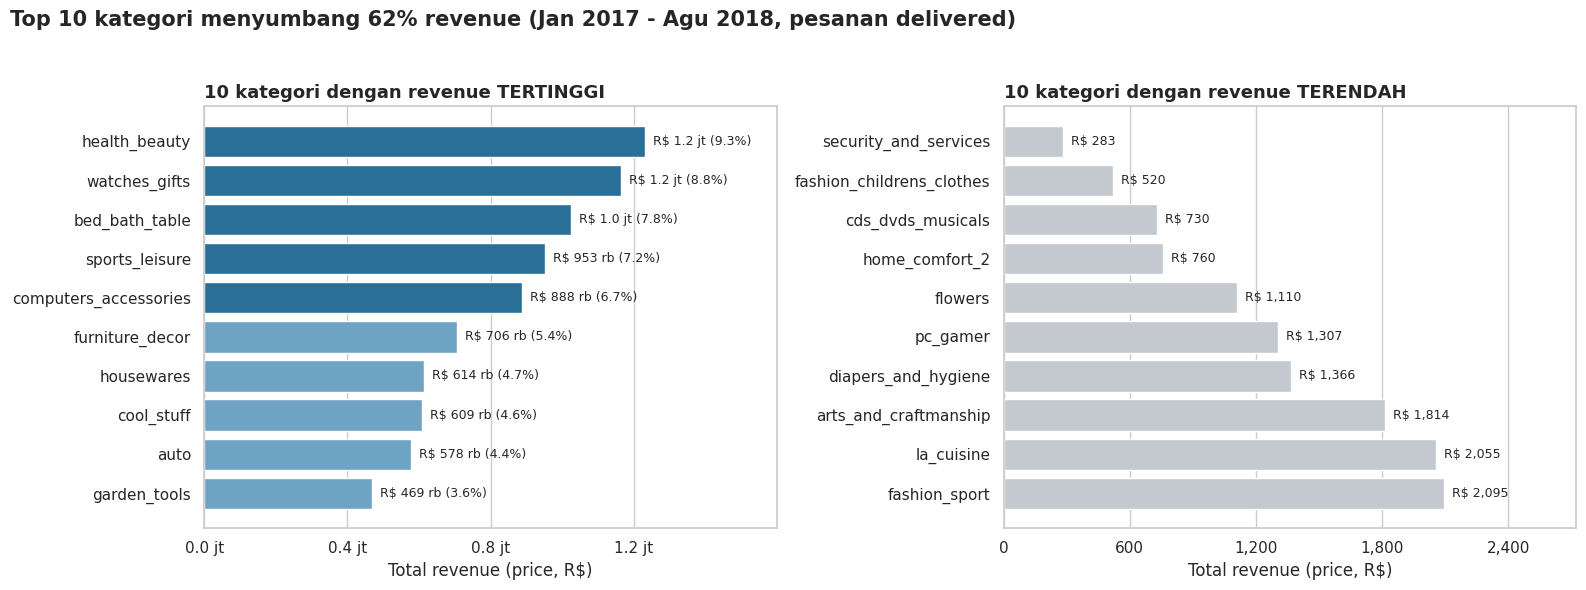

In [18]:
def fmt_money(v, pos=None):
    return f"R$ {v/1e6:.1f} jt" if v >= 1e6 else f"R$ {v/1e3:.0f} rb"

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top10 = cat_rev.head(10).sort_values("revenue")
axes[0].barh(top10.index, top10.revenue, color=[BLUE if i >= 5 else "#6fa3c4" for i in range(10)])
axes[0].set_title("10 kategori dengan revenue TERTINGGI", loc="left", fontsize=13, fontweight="bold")
for y, (v, s) in enumerate(zip(top10.revenue, top10.share_pct)):
    axes[0].text(v, y, f"  {fmt_money(v)} ({s:.1f}%)", va="center", fontsize=9)
axes[0].set_xlim(0, top10.revenue.max() * 1.3)

bottom10 = cat_rev.tail(10).sort_values("revenue", ascending=False)
axes[1].barh(bottom10.index, bottom10.revenue, color=GREY)
axes[1].set_title("10 kategori dengan revenue TERENDAH", loc="left", fontsize=13, fontweight="bold")
for y, v in enumerate(bottom10.revenue):
    axes[1].text(v, y, f"  R$ {v:,.0f}", va="center", fontsize=9)
axes[1].set_xlim(0, bottom10.revenue.max() * 1.3)

axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v/1e6:.1f} jt"))
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: f"{v:,.0f}"))
for ax in axes:
    ax.xaxis.set_major_locator(mtick.MaxNLocator(5))
    ax.set_xlabel("Total revenue (price, R$)"); ax.set_ylabel("")
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Top 10 kategori menyumbang {cat_rev.head(10).share_pct.sum():.0f}% revenue (Jan 2017 - Agu 2018, pesanan delivered)",
             fontsize=15, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

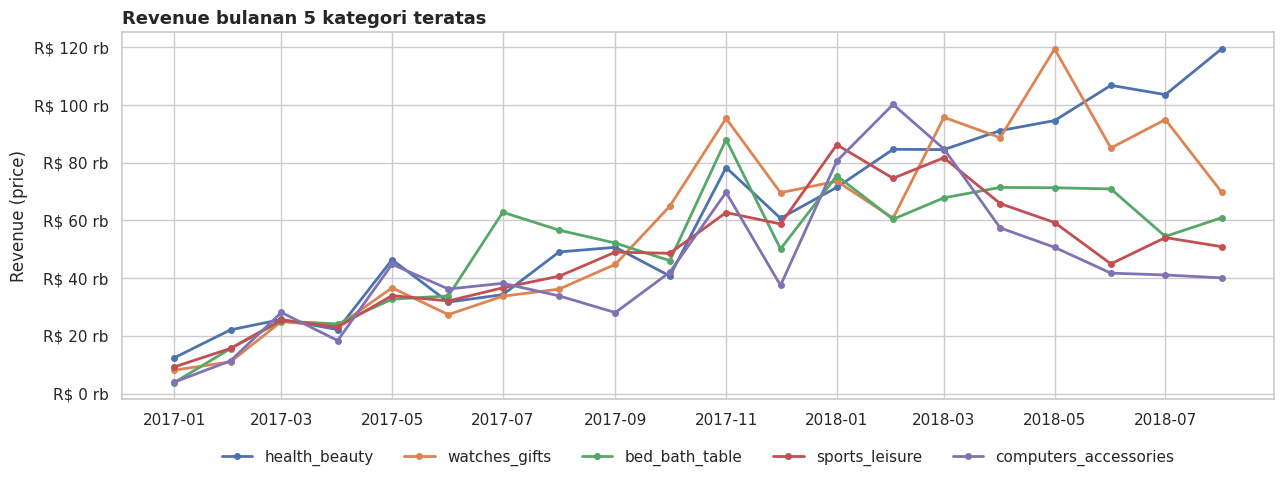

In [19]:
# Tren bulanan 5 kategori teratas: apakah dominasinya stabil?
top5 = cat_rev.head(5).index
trend = (main_df[main_df.product_category.isin(top5)]
         .assign(month=lambda d: pd.to_datetime(d.order_purchase_timestamp).dt.to_period("M").dt.to_timestamp())
         .pivot_table(index="month", columns="product_category", values="price", aggfunc="sum")[list(top5)])

fig, ax = plt.subplots(figsize=(13, 5))
palette = sns.color_palette("deep", 5)
for col, color in zip(trend.columns, palette):
    ax.plot(trend.index, trend[col], marker="o", ms=4, lw=2, label=col, color=color)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_money))
ax.set_title("Revenue bulanan 5 kategori teratas", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("Revenue (price)")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout(); plt.show()

### Pertanyaan 2: Keterlambatan pengiriman, review score, dan wilayah

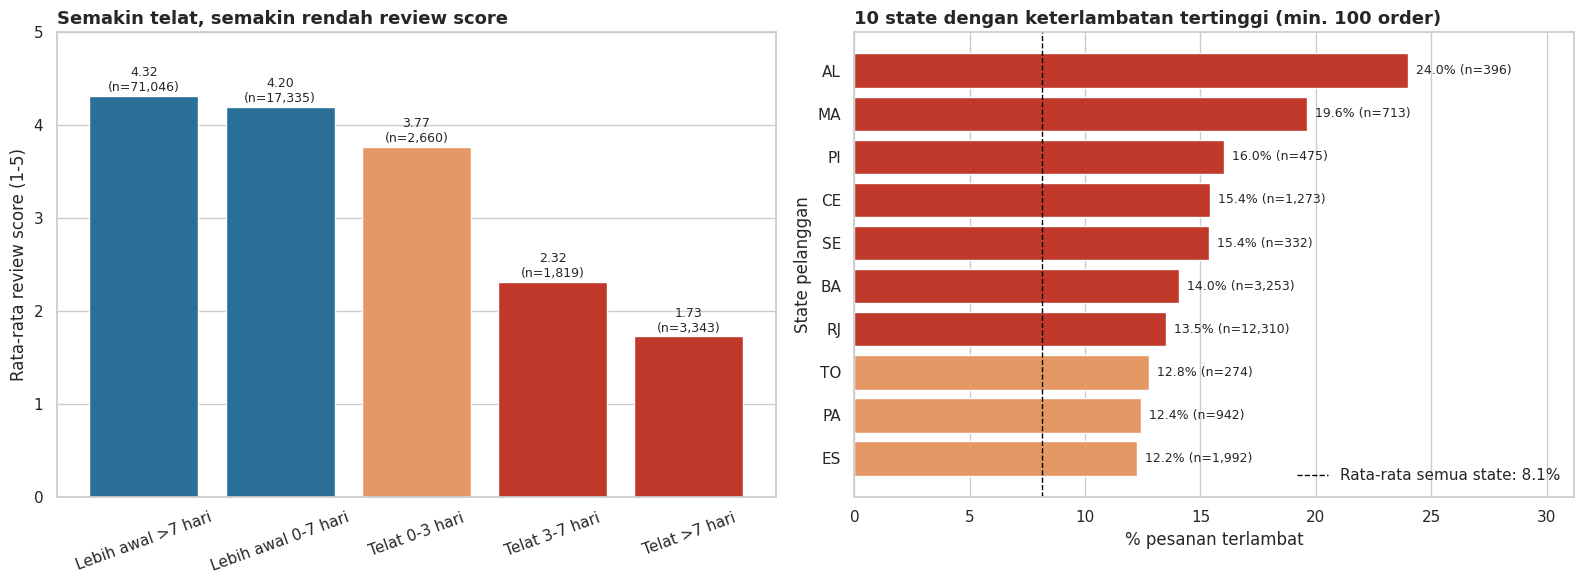

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# (a) Review score per kelompok ketepatan waktu
colors = [BLUE, BLUE, "#e59866", RED, RED]
bars = axes[0].bar(delay_review.index.astype(str), delay_review.avg_review, color=colors)
for b, n in zip(bars, delay_review.orders):
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.05,
                 f"{b.get_height():.2f}\n(n={n:,})", ha="center", fontsize=9)
axes[0].set_ylim(0, 5); axes[0].set_ylabel("Rata-rata review score (1-5)")
axes[0].set_title("Semakin telat, semakin rendah review score", loc="left", fontsize=13, fontweight="bold")
axes[0].tick_params(axis="x", rotation=20); axes[0].grid(axis="x", visible=False)

# (b) 10 state dengan % keterlambatan tertinggi (>=100 order)
top_late = state_rank.head(10).sort_values("late_pct")
axes[1].barh(top_late.index, top_late.late_pct, color=[RED if p > 13 else "#e59866" for p in top_late.late_pct])
overall = order_df.is_late.mean() * 100
axes[1].axvline(overall, color="black", ls="--", lw=1, label=f"Rata-rata semua state: {overall:.1f}%")
axes[1].legend(loc="lower right", frameon=False)
for y, (p, n) in enumerate(zip(top_late.late_pct, top_late.orders)):
    axes[1].text(p, y, f"  {p:.1f}% (n={n:,})", va="center", fontsize=9)
axes[1].set_xlim(0, top_late.late_pct.max() * 1.3)
axes[1].set_xlabel("% pesanan terlambat"); axes[1].set_ylabel("State pelanggan")
axes[1].set_title("10 state dengan keterlambatan tertinggi (min. 100 order)", loc="left", fontsize=13, fontweight="bold")
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Insight:**

- **Pertanyaan 1:** `health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, dan `computers_accessories` adalah lima kategori teratas (≈40% revenue), dan kelimanya konsisten memimpin sepanjang periode. Sepuluh kategori terbawah (mis. `security_and_services`, `fashion_childrens_clothes`) masing-masing hanya menghasilkan kurang dari R$ 2.200.
- **Pertanyaan 2:** penurunan review mulai terlihat pada keterlambatan 0–3 hari (3,77) dan **jatuh tajam** pada keterlambatan >3 hari (2,32 → 1,73). Enam state di Nordeste (AL, MA, PI, CE, SE, BA) serta RJ memiliki persentase keterlambatan jauh di atas rata-rata (8,1%).
- *Catatan:* hubungan keterlambatan–review bersifat korelasi; faktor lain (kualitas produk, dll.) turut berpengaruh.

## Analisis Lanjutan (Opsional)

### RFM Analysis
**Tujuan:** mengelompokkan pelanggan berdasarkan perilaku belanja agar strategi retensi dan promosi bisa dibedakan per segmen.
- **Recency:** jumlah hari sejak pembelian terakhir (acuan: 1 hari setelah order terakhir pada data)
- **Frequency:** jumlah pesanan unik per `customer_unique_id`
- **Monetary:** total `price` yang dibelanjakan

Skor R dan M dibuat memakai kuintil (1–5); skor F memakai *manual grouping* karena ±97% pelanggan hanya membeli sekali. Segmen ditentukan dengan aturan bisnis (manual grouping), bukan algoritma machine learning.

In [21]:
ref_date = main_df.order_purchase_timestamp.pipe(pd.to_datetime).max() + pd.Timedelta(days=1)

rfm = (main_df.assign(order_purchase_timestamp=pd.to_datetime(main_df.order_purchase_timestamp))
       .groupby("customer_unique_id")
       .agg(last_purchase=("order_purchase_timestamp", "max"),
            frequency=("order_id", "nunique"), monetary=("price", "sum")))
rfm["recency"] = (ref_date - rfm.last_purchase).dt.days

rfm["R"] = pd.qcut(rfm.recency, 5, labels=[5, 4, 3, 2, 1]).astype(int)          # makin baru makin tinggi
rfm["F"] = np.select([rfm.frequency == 1, rfm.frequency == 2], [1, 2], 3)         # 1x, 2x, >=3x
rfm["M"] = pd.qcut(rfm.monetary.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(row):
    if row.frequency >= 2:               return "Repeat Customers"
    if row.R >= 4 and row.M >= 4:        return "Recent High-Spenders"
    if row.R >= 4:                       return "Recent Customers"
    if row.R <= 2 and row.M >= 4:        return "At-Risk High-Spenders"
    if row.R <= 2:                       return "Dormant"
    return "Need Attention"

rfm["segment"] = rfm.apply(segment, axis=1)
seg = (rfm.groupby("segment")
       .agg(customers=("monetary", "size"), revenue=("monetary", "sum"),
            avg_recency=("recency", "mean"), avg_monetary=("monetary", "mean")))
seg["customers_pct"] = seg.customers / seg.customers.sum() * 100
seg["revenue_pct"] = seg.revenue / seg.revenue.sum() * 100
seg = seg.sort_values("revenue_pct", ascending=False)
print(f"Pelanggan yang membeli >1x : {(rfm.frequency > 1).mean()*100:.1f}%")
seg

Pelanggan yang membeli >1x : 3.0%


,customers,revenue,avg_recency,avg_monetary,customers_pct,revenue_pct
segment,,,,,,
Recent High-Spenders,14523,"3,877,864.64",91.91,267.02,15.60,29.42
At-Risk High-Spenders,13644,"3,776,428.57",392.61,276.78,14.66,28.65
Need Attention,18106,"2,350,181.26",220.46,129.80,19.45,17.83
Dormant,22335,"1,245,280.98",393.70,55.75,23.99,9.45
Recent Customers,21699,"1,204,667.46",89.77,55.52,23.31,9.14
Repeat Customers,2789,"725,355.04",219.60,260.08,3.00,5.50


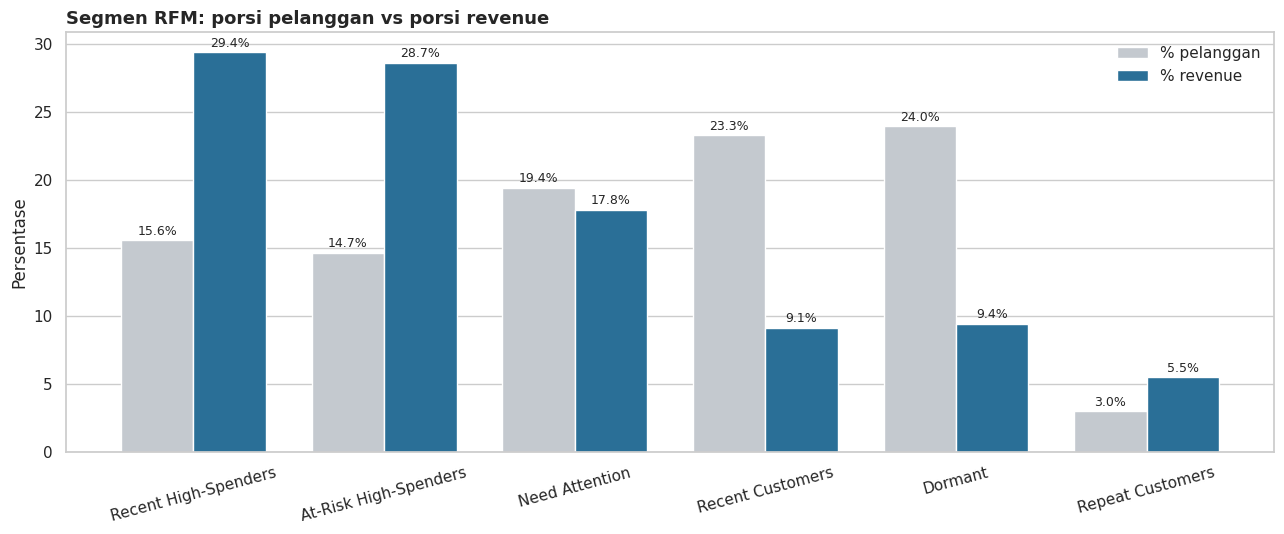

In [22]:
order_seg = ["Recent High-Spenders", "At-Risk High-Spenders", "Need Attention",
             "Recent Customers", "Dormant", "Repeat Customers"]
plot_seg = seg.loc[order_seg, ["customers_pct", "revenue_pct"]]

fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(len(plot_seg)); w = 0.38
ax.bar(x - w/2, plot_seg.customers_pct, w, label="% pelanggan", color=GREY)
ax.bar(x + w/2, plot_seg.revenue_pct, w, label="% revenue", color=BLUE)
for i, (c, r) in enumerate(zip(plot_seg.customers_pct, plot_seg.revenue_pct)):
    ax.text(i - w/2, c + 0.4, f"{c:.1f}%", ha="center", fontsize=9)
    ax.text(i + w/2, r + 0.4, f"{r:.1f}%", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(plot_seg.index, rotation=15)
ax.set_ylabel("Persentase"); ax.grid(axis="x", visible=False)
ax.set_title("Segmen RFM: porsi pelanggan vs porsi revenue", loc="left", fontsize=13, fontweight="bold")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

### Geospatial Analysis
**Tujuan:** melihat sebaran pesanan dan keterlambatan secara geografis. Setiap gelembung adalah **titik tengah pelanggan per state** (dari koordinat kode pos): ukuran = jumlah pesanan, warna = persentase pesanan terlambat.

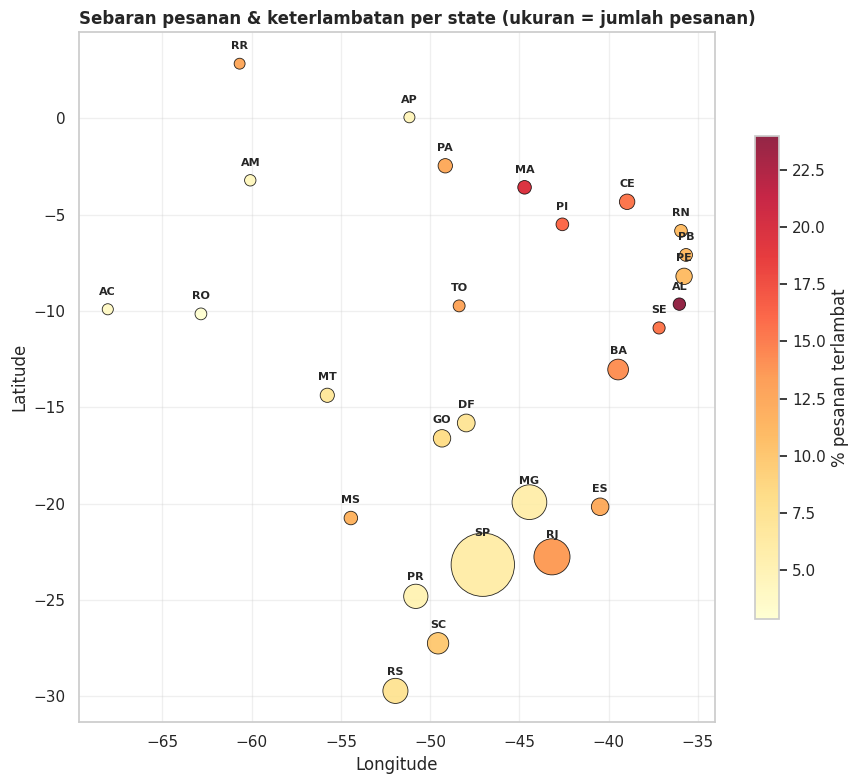

In [23]:
geo_state = (order_df.dropna(subset=["geolocation_lat"])
             .groupby("customer_state")
             .agg(lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean"))
             .join(state_stats[["orders", "late_pct"]]))

fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(geo_state.lng, geo_state.lat, s=geo_state.orders / 20 + 60, c=geo_state.late_pct,
                cmap="YlOrRd", edgecolor="black", linewidth=0.6, alpha=0.85)
for st, r in geo_state.iterrows():
    ax.annotate(st, (r.lng, r.lat), xytext=(0, 9 + min(r.orders / 4000, 12)), textcoords="offset points",
                ha="center", va="bottom", fontsize=8, fontweight="bold")
cb = plt.colorbar(sc, ax=ax, shrink=0.7); cb.set_label("% pesanan terlambat")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Sebaran pesanan & keterlambatan per state (ukuran = jumlah pesanan)", loc="left", fontsize=12, fontweight="bold")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Insight:**

- **RFM:** hanya **3,0%** pelanggan yang membeli lebih dari sekali, sehingga bisnis sangat bergantung pada akuisisi pelanggan baru.
- *Recent High-Spenders* (15,6% pelanggan) menyumbang **29,4%** revenue, sedangkan *At-Risk High-Spenders* (14,7% pelanggan, rata-rata terakhir belanja ±393 hari lalu) menyumbang **28,7%** revenue. Kelompok ini adalah target utama retensi/win-back.
- *Dormant* (24,0% pelanggan) hanya menyumbang 9,5% revenue sehingga prioritas win-back-nya rendah.
- **Geospatial:** pesanan terkonsentrasi di Tenggara/Selatan (SP, RJ, MG = ±67% pesanan; SP saja ±42%), sedangkan gelembung berwarna merah tua (keterlambatan tinggi) berada di Nordeste (AL, MA, PI, CE, SE).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Revenue sangat terkonsentrasi: 10 kategori teratas menyumbang **62,5%** dari total revenue R$ 13,18 juta, dipimpin `health_beauty` (R$ 1,23 juta; 9,3%), `watches_gifts` (R$ 1,16 juta; 8,8%), dan `bed_bath_table` (R$ 1,02 juta; 7,8%). Sebaliknya, 10 kategori terbawah hanya menyumbang **0,09%** revenue (masing-masing < R$ 2.200).
- **Conclusion pertanyaan 2:** Pesanan terlambat memiliki rata-rata review **2,57** dibanding **4,29** untuk pesanan tepat waktu (selisih **1,73 poin**), dan pada keterlambatan >7 hari sebanyak 76% review bernilai 1–2. Persentase keterlambatan tertinggi ada di **AL (24,0%), MA (19,6%), PI (16,0%), CE, SE, dan BA**, sedangkan **RJ** menyumbang paling banyak pesanan terlambat secara absolut (21,3% dari seluruh keterlambatan).
- **Temuan analisis lanjutan:** hanya 3,0% pelanggan yang membeli ulang, dan 14,7% pelanggan *At-Risk High-Spenders* menyumbang 28,7% revenue namun sudah lama tidak berbelanja.

**Rekomendasi Action Item:**
- **Fokuskan stok, promosi, dan akuisisi seller pada 5 kategori teratas** (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`). Gunakan bundling/promo ongkir pada `bed_bath_table` (volume tinggi) dan promo premium pada `watches_gifts` (harga rata-rata tinggi). Untuk kategori dengan revenue sangat kecil, evaluasi ulang apakah layak dipertahankan atau digabung dalam kampanye kategori lain sebelum menambah investasi.
- **Perbaiki logistik di wilayah prioritas:** (1) Nordeste (AL, MA, PI, CE, SE, BA) dengan evaluasi/penambahan mitra kurir dan estimasi tiba per state yang lebih realistis, (2) RJ karena volumenya besar. Kirim notifikasi proaktif dan berikan kompensasi (mis. voucher) bila pesanan diprediksi terlambat >3 hari, sebab pada kelompok ini 60–76% review bernilai 1–2.
- **Jalankan kampanye win-back untuk *At-Risk High-Spenders*** (13.644 pelanggan, ±R$ 3,78 juta revenue historis) dan **insentif pembelian kedua** untuk *Recent High-Spenders* (14.523 pelanggan) guna menaikkan rasio pembelian ulang yang baru 3,0%.